In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

groups = pd.read_csv('ab_test_users_groups.csv')
events = pd.read_csv('ab_test_events.csv')

print("--- ИНФОРМАЦИЯ О ГРУППАХ ---")
print(groups.info())
print("\nПервые 5 строк:")
display(groups.head())

print("\n--- ИНФОРМАЦИЯ О СОБЫТИЯХ ---")
print(events.info())
print("\nПервые 5 строк:")
display(events.head())

# ПРОВЕРКА 1: Пересечение пользователей
users_in_both = groups.groupby('user_id')['group'].nunique()
overlap_users = users_in_both[users_in_both > 1]

print(f"\nКоличество пользователей, попавших в обе группы: {len(overlap_users)}")
if len(overlap_users) > 0:
    print("ВНИМАНИЕ! Есть пересечения. Их нужно будет удалить.")
else:
    print("Пересечений нет. Отлично!")

# ПРОВЕРКА 2: SRM
group_counts = groups['group'].value_counts()
print("\nКоличество пользователей по группам:")
print(group_counts)

#Доля
ratio = group_counts / len(groups)
print("\nДоли групп:")
print(ratio)

--- ИНФОРМАЦИЯ О ГРУППАХ ---
<class 'pandas.DataFrame'>
RangeIndex: 6008 entries, 0 to 6007
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   user_id      6008 non-null   str  
 1   group        6008 non-null   str  
 2   signup_date  6008 non-null   str  
 3   grade        6008 non-null   int64
dtypes: int64(1), str(3)
memory usage: 187.9 KB
None

Первые 5 строк:


,user_id,group,signup_date,grade
0,U300000,B,2026-03-09,5
1,U300001,B,2025-09-07,9
2,U300002,B,2026-01-11,9
3,U300003,A,2025-06-07,5
4,U300004,B,2025-12-25,11



--- ИНФОРМАЦИЯ О СОБЫТИЯХ ---
<class 'pandas.DataFrame'>
RangeIndex: 179330 entries, 0 to 179329
Data columns (total 3 columns):
 #   Column      Non-Null Count   Dtype
---  ------      --------------   -----
 0   user_id     179330 non-null  str  
 1   timestamp   179330 non-null  str  
 2   event_type  179330 non-null  str  
dtypes: str(3)
memory usage: 4.1 MB
None

Первые 5 строк:


,user_id,timestamp,event_type
0,U300281,2026-05-04 00:06:44,homework_completed
1,U300733,2026-05-04 00:19:56,homework_completed
2,U304499,2026-05-04 00:22:07,login
3,U304266,2026-05-04 00:23:42,homework_started
4,U304266,2026-05-04 00:23:42,homework_started



Количество пользователей, попавших в обе группы: 8
ВНИМАНИЕ! Есть пересечения. Их нужно будет удалить.

Количество пользователей по группам:
group
A    3005
B    3003
Name: count, dtype: int64

Доли групп:
group
A    0.500166
B    0.499834
Name: count, dtype: float64


In [3]:
# удаляем пользователей, которые есть в обеих группах
valid_users = groups.groupby('user_id').filter(lambda x: len(x) == 1)

groups_clean = valid_users.copy()
events_clean = events[events['user_id'].isin(groups_clean['user_id'])].copy()

print(f"Пользователей после чистки: {len(groups_clean)} (было 6008)")
print(f"Событий после чистки: {len(events_clean)} (было 179330)")

# проверяем SRM 
counts = groups_clean['group'].value_counts()
print(f"\nГруппа A: {counts['A']}")
print(f"Группа B: {counts['B']}")

# тест пирсона для проверки равномерности
expected = [len(groups_clean) / 2, len(groups_clean) / 2]
observed = [counts['A'], counts['B']]

chi2, p_value = stats.chisquare(observed, expected)

print(f"\np-value для SRM-теста: {p_value:.4f}")
if p_value < 0.05:
    print("ВНИМАНИЕ! SRM обнаружен. Сплитование было неравномерным. Результаты могут быть невалидны.")
else:
    print("SRM не обнаружен. Сплитование корректное (разница случайна).")

Пользователей после чистки: 5992 (было 6008)
Событий после чистки: 179113 (было 179330)

Группа A: 2997
Группа B: 2995

p-value для SRM-теста: 0.9794
SRM не обнаружен. Сплитование корректное (разница случайна).


In [4]:
print("Уникальные типы событий и их количество:")
print(events_clean['event_type'].value_counts())

events_clean['timestamp'] = pd.to_datetime(events_clean['timestamp'])

Уникальные типы событий и их количество:
event_type
login                 75460
homework_started      68229
homework_completed    28963
return_visit_d7        4514
return_visit_d14       1947
Name: count, dtype: int64


In [5]:
# считаем факт того, что пользователь совершил событие 
user_events = events_clean.groupby('user_id')['event_type'].apply(lambda x: set(x)).reset_index()
user_events.columns = ['user_id', 'events_set']

user_events['is_retention_d7'] = user_events['events_set'].apply(lambda x: 1 if 'return_visit_d7' in x else 0)
user_events['is_retention_d14'] = user_events['events_set'].apply(lambda x: 1 if 'return_visit_d14' in x else 0)
user_events['is_homework_completed'] = user_events['events_set'].apply(lambda x: 1 if 'homework_completed' in x else 0)

# объединяем с таблицей групп (кто в A, а кто в B)
df_merged = groups_clean.merge(user_events, on='user_id', how='left')

df_merged[['is_retention_d7', 'is_retention_d14', 'is_homework_completed']] = df_merged[['is_retention_d7', 'is_retention_d14', 'is_homework_completed']].fillna(0)

# ср значения метрик по группам
metrics = df_merged.groupby('group')[['is_retention_d7', 'is_retention_d14', 'is_homework_completed']].mean()
print("Метрики по группам:")
display(metrics)

print("\nРазница между группами (B - A):")
print(metrics.loc['B'] - metrics.loc['A'])

Метрики по группам:


,is_retention_d7,is_retention_d14,is_homework_completed
group,,,
A,0.727060,0.287621,0.976310
B,0.779633,0.362270,0.988314



Разница между группами (B - A):
is_retention_d7          0.052572
is_retention_d14         0.074649
is_homework_completed    0.012004
dtype: float64


In [6]:
from scipy.stats import chi2_contingency

# проверка значимости разницы между двумя долями
def test_proportions(group_a, group_b, metric_name):
    count_a = group_a[metric_name].sum()
    nobs_a = len(group_a)
    count_b = group_b[metric_name].sum()
    nobs_b = len(group_b)
    
    contingency_table = [
        [count_a, nobs_a - count_a],
        [count_b, nobs_b - count_b]
    ]
    
    chi2, p_value, dof, expected = chi2_contingency(contingency_table)
    
    print(f"--- Метрика: {metric_name} ---")
    print(f"Конверсия в A: {count_a / nobs_a:.4f}")
    print(f"Конверсия в B: {count_b / nobs_b:.4f}")
    print(f"p-value: {p_value:.6f}")
    
    if p_value < 0.05:
        print("РЕЗУЛЬТАТ: Разница статистически значима\n")
    else:
        print("РЕЗУЛЬТАТ: Разница НЕ значима\n")

group_a = df_merged[df_merged['group'] == 'A']
group_b = df_merged[df_merged['group'] == 'B']

test_proportions(group_a, group_b, 'is_retention_d7')
test_proportions(group_a, group_b, 'is_retention_d14')
test_proportions(group_a, group_b, 'is_homework_completed')

--- Метрика: is_retention_d7 ---
Конверсия в A: 0.7271
Конверсия в B: 0.7796
p-value: 0.000003
РЕЗУЛЬТАТ: Разница статистически значима

--- Метрика: is_retention_d14 ---
Конверсия в A: 0.2876
Конверсия в B: 0.3623
p-value: 0.000000
РЕЗУЛЬТАТ: Разница статистически значима

--- Метрика: is_homework_completed ---
Конверсия в A: 0.9763
Конверсия в B: 0.9883
p-value: 0.000611
РЕЗУЛЬТАТ: Разница статистически значима



Колонки в df_segmented: ['user_id', 'group', 'signup_date', 'grade', 'events_set', 'is_retention_d7', 'is_retention_d14', 'is_homework_completed']

Эффект геймификации на Retention 7 по классам:


group,A,B,effect (B - A),effect_pp
grade,,,,
5,0.7287,0.8245,0.0958,9.5820
6,0.7562,0.8645,0.1084,10.8364
7,0.7072,0.8444,0.1372,13.7198
8,0.7357,0.7755,0.0398,3.9780
9,0.7169,0.7836,0.0667,6.6704
10,0.7122,0.6986,-0.0136,-1.3565
11,0.7291,0.6612,-0.0678,-6.7849


C:\Users\user\AppData\Local\Temp\ipykernel_13728\2873941664.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=segment_metrics.index, y='effect_pp', data=segment_metrics, palette='coolwarm')


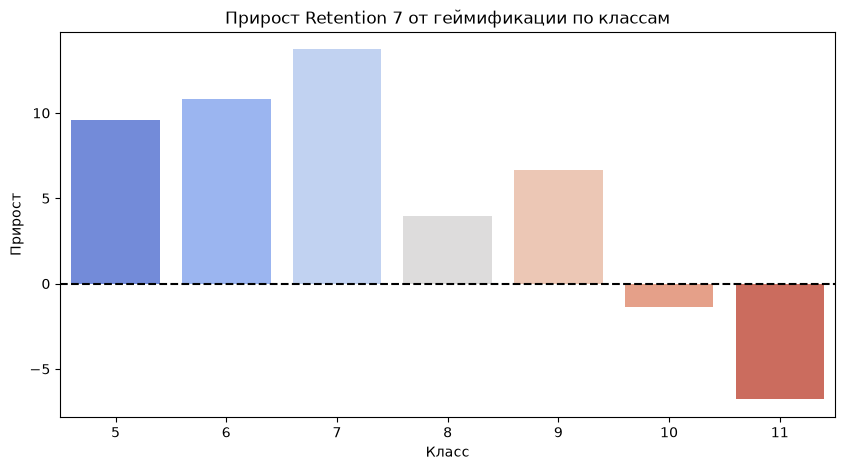

In [7]:
if 'grade' not in df_merged.columns:
    df_segmented = df_merged.merge(groups_clean[['user_id', 'grade']], on='user_id', how='left')
else:
    df_segmented = df_merged.copy()

print("Колонки в df_segmented:", df_segmented.columns.tolist())

# Retention 7 по классам и группам
segment_metrics = df_segmented.groupby(['grade', 'group'])['is_retention_d7'].mean().unstack()

# эффект для каждого класса
segment_metrics['effect (B - A)'] = segment_metrics['B'] - segment_metrics['A']
segment_metrics['effect_pp'] = segment_metrics['effect (B - A)'] * 100 

print("\nЭффект геймификации на Retention 7 по классам:")
display(segment_metrics.round(4))

plt.figure(figsize=(10, 5))
sns.barplot(x=segment_metrics.index, y='effect_pp', data=segment_metrics, palette='coolwarm')
plt.title('Прирост Retention 7 от геймификации по классам')
plt.xlabel('Класс')
plt.ylabel('Прирост')
plt.axhline(0, color='black', linestyle='--') 
plt.show()

Воронка в абсолютных числах (уникальные пользователи):


,Login,HW Started,HW Completed
Group,,,
A,2997,2997,2926
B,2995,2995,2960



Воронка в процентах (относительно логина):


,Login,HW Started,HW Completed
Group,,,
A,100.0,100.0,97.63
B,100.0,100.0,98.83


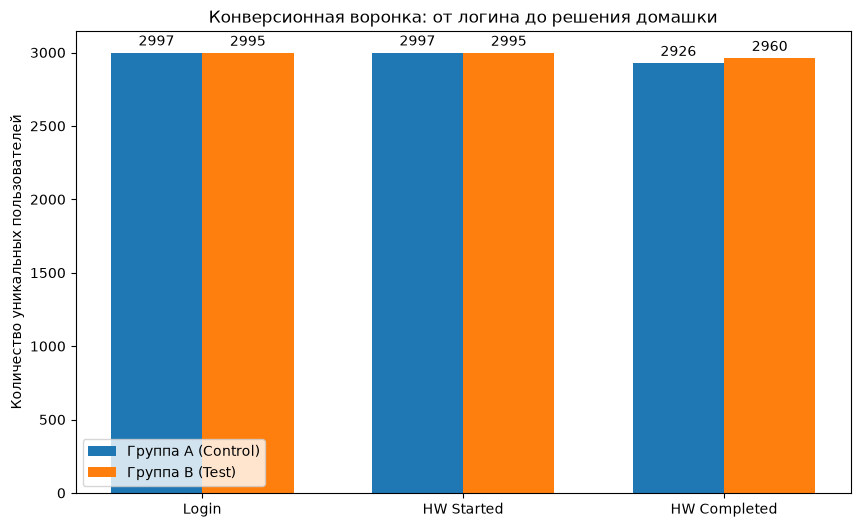

In [8]:
import matplotlib.pyplot as plt
import numpy as np

# количество уникальных пользователей, совершивших каждое событие, по группам
funnel_data = []
for group_name in ['A', 'B']:
    group_users = groups_clean[groups_clean['group'] == group_name]['user_id']
    group_events = events_clean[events_clean['user_id'].isin(group_users)]
    
    logins = group_events[group_events['event_type'] == 'login']['user_id'].nunique()
    hw_started = group_events[group_events['event_type'] == 'homework_started']['user_id'].nunique()
    hw_completed = group_events[group_events['event_type'] == 'homework_completed']['user_id'].nunique()
    
    funnel_data.append({'Group': group_name, 'Login': logins, 'HW Started': hw_started, 'HW Completed': hw_completed})

funnel_df = pd.DataFrame(funnel_data).set_index('Group')

# конверсия в процентах (относительно первого шага)
funnel_pct = funnel_df.div(funnel_df['Login'], axis=0) * 100

print("Воронка в абсолютных числах (уникальные пользователи):")
display(funnel_df)
print("\nВоронка в процентах (относительно логина):")
display(funnel_pct.round(2))

labels = ['Login', 'HW Started', 'HW Completed']
x = np.arange(len(labels))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))
rects1 = ax.bar(x - width/2, funnel_df.loc['A'], width, label='Группа A (Control)', color='#1f77b4')
rects2 = ax.bar(x + width/2, funnel_df.loc['B'], width, label='Группа B (Test)', color='#ff7f0e')

ax.set_ylabel('Количество уникальных пользователей')
ax.set_title('Конверсионная воронка: от логина до решения домашки')
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.legend()
ax.bar_label(rects1, padding=3)
ax.bar_label(rects2, padding=3)

plt.show()

In [10]:
import numpy as np
from statsmodels.stats.proportion import proportion_confint
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize

# доверительные интервалы
print("=== 95% Доверительные интервалы (CI) для разницы метрик ===")
for metric in ['is_retention_d7', 'is_retention_d14', 'is_homework_completed']:
    count_a = group_a[metric].sum()
    nobs_a = len(group_a)
    count_b = group_b[metric].sum()
    nobs_b = len(group_b)
    
    p1 = count_a / nobs_a
    p2 = count_b / nobs_b
    diff = p2 - p1
    
    se = np.sqrt((p1 * (1 - p1) / nobs_a) + (p2 * (1 - p2) / nobs_b))
    
    ci_lower = diff - 1.96 * se
    ci_upper = diff + 1.96 * se
    
    print(f"\nМетрика: {metric}")
    print(f"Разница (B - A): {diff:.4f}")
    print(f"95% CI: [{ci_lower:.4f}, {ci_upper:.4f}]")
    if ci_lower > 0:
         print("Вывод: Эффект положительный и значимый (интервал не включает 0).")

# расчет MDE
print("\n=== Минимальный обнаруживаемый эффект (MDE) ===")
baseline_p = group_a['is_retention_d7'].mean()
power = 0.8
alpha = 0.05
nobs = len(group_a)

analysis = NormalIndPower()
# MDE через эффект размера
effect_size = analysis.solve_power(effect_size=None, nobs1=nobs, alpha=alpha, power=power, ratio=1.0)
print(f"MDE для Retention 7 {effect_size:.4f}")
print("Можем заметить изменение метрики, начиная примерно с этого значения.")

# ttv
print("\n=== Скорость выполнения первой домашки ===")
hw_events = events_clean[events_clean['event_type'].isin(['homework_started', 'homework_completed'])].copy()
hw_events = hw_events.sort_values(by=['user_id', 'timestamp'])

first_started = hw_events[hw_events['event_type'] == 'homework_started'].groupby('user_id')['timestamp'].min().reset_index()
first_started.columns = ['user_id', 'start_time']

first_completed = hw_events[hw_events['event_type'] == 'homework_completed'].groupby('user_id')['timestamp'].min().reset_index()
first_completed.columns = ['user_id', 'end_time']

ttv = first_started.merge(first_completed, on='user_id', how='inner')
ttv['time_to_value_min'] = (ttv['end_time'] - ttv['start_time']).dt.total_seconds() / 60

ttv = ttv.merge(groups_clean[['user_id', 'group']], on='user_id')

ttv_stats = ttv.groupby('group')['time_to_value_min'].agg(['mean', 'median', 'count'])
print("Время выполнения первого ДЗ (в минутах):")
display(ttv_stats.round(2))

=== 95% Доверительные интервалы (CI) для разницы метрик ===

Метрика: is_retention_d7
Разница (B - A): 0.0526
95% CI: [0.0308, 0.0744]
Вывод: Эффект положительный и значимый (интервал не включает 0).

Метрика: is_retention_d14
Разница (B - A): 0.0746
95% CI: [0.0510, 0.0983]
Вывод: Эффект положительный и значимый (интервал не включает 0).

Метрика: is_homework_completed
Разница (B - A): 0.0120
95% CI: [0.0053, 0.0187]
Вывод: Эффект положительный и значимый (интервал не включает 0).

=== Минимальный обнаруживаемый эффект (MDE) ===
MDE для Retention 7 0.0724
Можем заметить изменение метрики, начиная примерно с этого значения.

=== Скорость выполнения первой домашки ===
Время выполнения первого ДЗ (в минутах):


,mean,median,count
group,,,
A,5055.27,2896.0,2926
B,3578.27,1403.0,2960


# Отчет по результатам A/B-тестирования механики геймификации

## 1. Бизнес-резюме
**Гипотеза:**  Внедрение элементов геймификации увеличит конверсию и метрики удержания.

**Результат:** Гипотеза подтверждена. Фича статистически значимо улучшает удержание (Retention 7 и 14) и конверсию в выполнение дз. Обнаружен парадокс Симпсона: геймификация работает по-разному для разных классов.

**Бизнес-решение:** Рекомендуется сегментированная раскатка. Внедрение геймификации для 5-9 классов и отказ от внедрения (или переработка механик) для 10-11 классов.

---

## 2. Проверка качества эксперимента
Перед расчетом метрик была проведена проверка валидности данных:
*   **Очистка:** Удалены 8 пользователей, попавших одновременно в обе группы, и их события.
*   **Проверка SRM:** Проведен тест Пирсона.
    *   *Группа A:* 2997 пользователей.
    *   *Группа B:* 2995 пользователей.
    *   *p-value = 0.9794* (значимо выше 0.05). Сплитование корректно, перекоса нет.

---

## 3. Анализ конверсионной воронки
*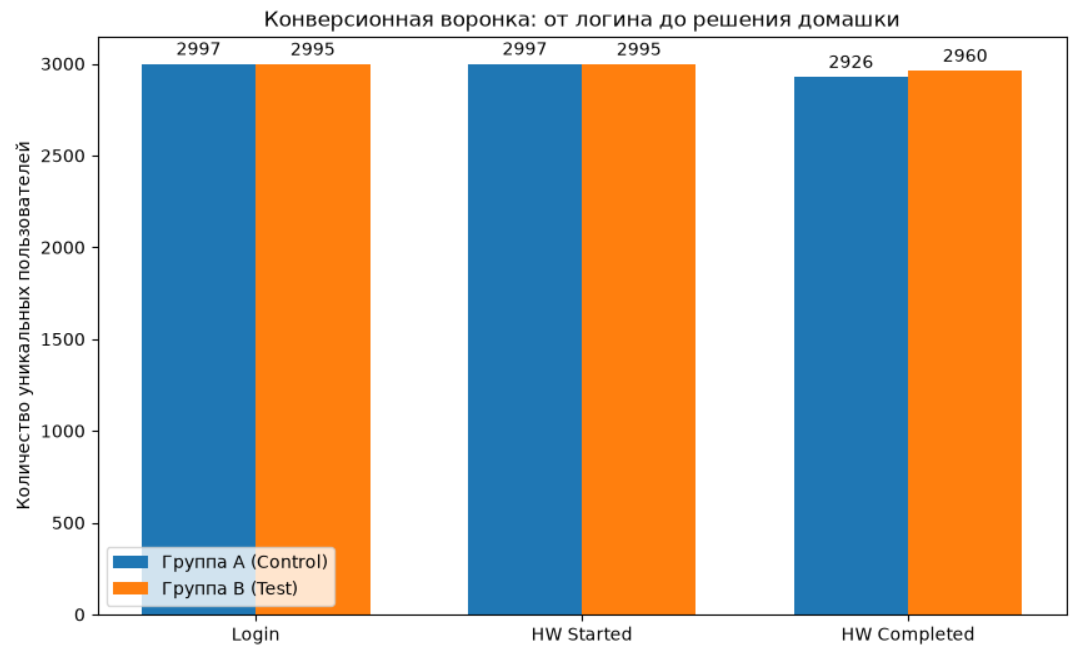*
**Результат:** Воронка показывает, что геймификация не влияет на начало выполнения задания (HW Started = 100% в обеих группах), но помогает довести задачу до конца. В группе B конверсия в выполнение (HW Completed) составила 98.83%, в группе A - 97.63%.

---

## 4. Анализ ключевых метрик
| Метрика | Группа A | Группа B | Прирост | 95% CI | p-value | Стат. значимость |
| :--- | :--- | :--- | :--- | :--- | :--- |:--- |
| **Retention 7** | 72.71% | 77.96% | **+5.25** | [3.08%; 7.44%] | 0.000003 | Значимо |
| **Retention 14** | 28.76% | 36.23% | **+7.47** | [5.10%; 9.83%] | 0.000000 | Значимо |
| **HW Completed** | 97.63% | 98.83% | **+1.20** | [0.53%; 1.87%] | 0.000611 | Значимо |

*Все доверительные интервалы положительные и не включают 0, что доказывает практическую значимость эффекта. MDE для Retention 7 составляет 7.24%.*

---

## 5. Скорость выполнения первой домашки
**Ключевой инсайт:** Геймификация значительно ускоряет вовлечение учеников в процесс. 
*   Медианное время выполнения первого ДЗ в группе A - 2896 минут (~48 часов).
*   В группе B (с геймификацией) - 1403 минуты (~23 часа).
*   *Вывод:* Фича мотивирует учеников приступать к задачам в 2 раза быстрее.

---

## 6. Сегментированный анализ
В ходе анализа было выявлено, что эффект геймификации различается в зависимости от класса ученика. Для проверки выборка была разбита по полю `grade`.
*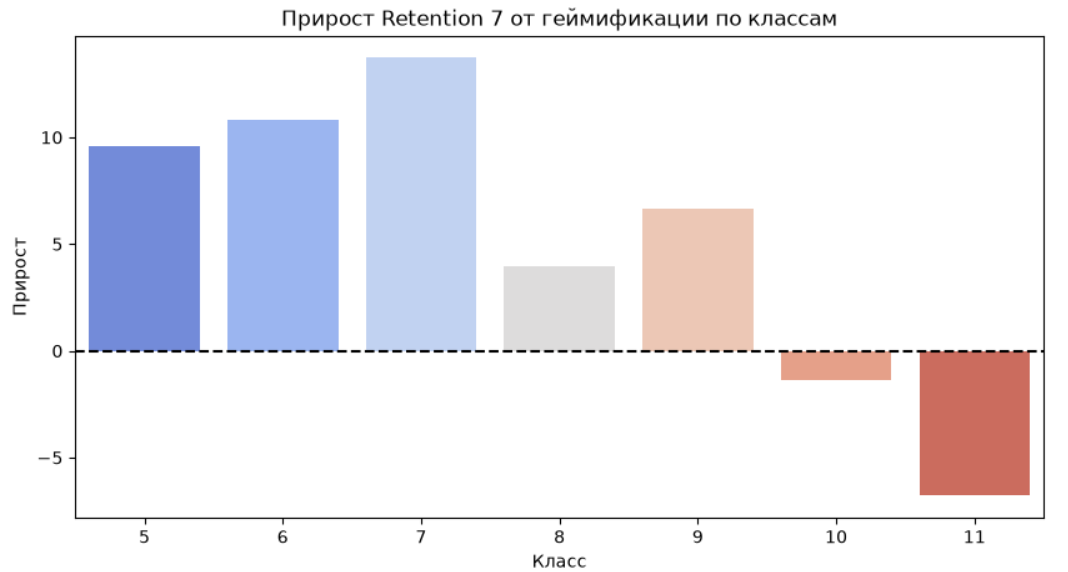*

**Прирост Retention 7 по классам:**

| Класс | Группа A | Группа B | Прирост (п.п.) | Вывод |
| :--- | :--- | :--- | :--- | :--- |
| **5 класс** | 72.87% | 82.45% | **+9.58** | Отличный эффект |
| **6 класс** | 75.62% | 86.45% | **+10.83** | Отличный эффект |
| **7 класс** | 70.72% | 84.44% | **+13.72** | Максимальный эффект |
| **8 класс** | 73.57% | 77.55% | **+3.98** | Положительный |
| **9 класс** | 71.69% | 78.36% | **+6.67** | Положительный |
| **10 класс** | 71.22% | 69.86% | **-1.36** | Отрицательный |
| **11 класс** | 72.91% | 66.12% | **-6.79** | Сильный отток |

**Парадокс Симпсона:** 
Общая метрика показывает рост (+5.2), но внутри сегментов картина иная. Геймификация приносит колоссальную пользу средним классам (пик на 7 классе: +13.7). Однако для выпускников (10-11 классы) эффект отрицательный. Механики достижений снижают удержание, что, вероятно, связано с фокусом на подготовке к экзаменам.

---

## 7. Итоговая бизнес-рекомендация

На основе статистического анализа и сегментации предлагается следующее решение:

1.  **Раскатить фичу:** Для 5-9 классов. Эффект статистически значим и приносит практическую пользу (особенно для 5-7 классов).
2.  **Отправить на доработку (не раскатывать):** Для 10-11 классов. Необходимо исследовать их потребности и предложить альтернативные механики (например, трекеры прогресса, дедлайны), вместо игровых элементов.
3.  **Глобальную раскатку отклонить:** Это приведет к неэффективному расходу ресурсов и потенциальному оттоку целевой аудитории выпускников.